# TP2 KASDAD - Klasifikasi `artifact_signal`

**EDA individual:** Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?

Routing (C4_HGB) memakai hybrid structured + TF-IDF Logistic Regression saat teks terisi, dan structured HGB saat kosong. Metrik utama: **Macro F1**.

Kelompok **A06 - KasdudLovers** | **Samuel Indriano** | NPM **2406400524**.

Notebook mencakup data, EDA, preprocessing, pemodelan, dan evaluasi temporal. Approach individual ini berbeda dari ensemble champion kelompok terbaru.

## 1. Persiapan dan data

Sediakan official `classification/Train.csv` di bawah `TP2_DATA_DIR` (default: `data/raw/` di current directory atau parent). `TP2_DATA_DIR` menunjuk folder yang berisi `classification/` dan `regression/`. Notebook ini memuat seluruh helper EDA, preprocessing, model, dan metrik custom di dalam cell; ia tidak mengimpor file project lokal. Test inference tetap nonaktif.

Dependensi Python: NumPy, pandas, SciPy, scikit-learn, Matplotlib, threadpoolctl, IPython/Jupyter.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from threadpoolctl import threadpool_limits


def find_data_root():
    configured = os.environ.get("TP2_DATA_DIR")
    if configured:
        root = Path(configured).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f"TP2_DATA_DIR is not a directory: {root}")
        return root
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate / "data" / "raw", candidate / "raw", candidate):
            if any((root / task).is_dir() for task in ("classification", "regression")):
                return root
    return current / "data" / "raw"


DATA_ROOT = find_data_root()


def task_files(task, root=None):
    if task not in {"classification", "regression"}:
        raise ValueError(f"Unknown task: {task}")
    folder = (Path(root) if root is not None else DATA_ROOT) / task
    files = {}
    for role, stem in (
        ("train", "train"),
        ("test", "test"),
        ("sample", "samplesubmission"),
    ):
        matches = [
            path
            for path in folder.iterdir()
            if path.is_file()
            and path.suffix.lower() == ".csv"
            and path.stem.lower() == stem
        ] if folder.is_dir() else []
        if len(matches) > 1:
            raise ValueError(f"Ambiguous {task}/{role}: {[path.name for path in matches]}")
        files[role] = matches[0] if matches else None
    return files


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def stream_missing_mask(frame):
    series = frame["signal_stream"] if isinstance(frame, pd.DataFrame) else frame
    return (
        series.isna()
        | series.fillna("").astype(str).str.strip().eq("")
    ).to_numpy(dtype=bool)


def array_digest(values):
    array = np.asarray(values, dtype="<f8")
    return hashlib.sha256(array.tobytes(order="C")).hexdigest()


plt.rcParams.update(
    {
        "figure.figsize": (9, 4.5),
        "figure.dpi": 120,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
get_ipython().run_line_magic("matplotlib", "inline")
print("Data root:", DATA_ROOT)
print("Set TP2_DATA_DIR to the parent of classification/ and regression/ if needed.")


Data root: C:\Users\Sam\AppData\Local\Temp\samuel_root_standalone_cx8uzsvi\data\raw
Set TP2_DATA_DIR to the parent of classification/ and regression/ if needed.


## 2. Dataset dan target

Label 1 berarti indikasi artefak eksploit publik teramati; label 0 tidak memastikan artefak tidak ada. Train mencakup cycle 47-79, Test 80-91. Validasi mengikuti waktu dan seluruh preprocessing dipelajari dari data fit.

Macro F1 memberi bobot sama pada F1 kedua kelas. Recipe TP1 dievaluasi ulang karena target TP2 berbeda.

In [2]:
EXPECTED_TRAIN_SHA256 = (
    "875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c"
)
DATA_FILES = task_files("classification")
if DATA_FILES["train"] is None:
    raise FileNotFoundError(
        "Letakkan official classification/Train.csv di bawah TP2_DATA_DIR atau data/raw/."
    )

train_path = DATA_FILES["train"]
train = pd.read_csv(train_path)
required = {
    "record_id", "cycle_code", "artifact_signal", "signal_stream",
    "impact_load", "entry_friction", "text_load",
}
missing = sorted(required - set(train.columns))
assert not missing, f"Kolom wajib tidak ditemukan: {missing}"
assert train["record_id"].notna().all() and train["record_id"].is_unique
assert train["artifact_signal"].notna().all()
assert set(train["artifact_signal"].unique()) == {0, 1}
assert train["cycle_code"].between(47, 79).all()

actual_train_sha256 = sha256_file(train_path)
assert actual_train_sha256 == EXPECTED_TRAIN_SHA256
positive_count = int(train["artifact_signal"].sum())
overview = pd.DataFrame(
    [
        {
            "Train rows": len(train),
            "feature columns": len(train.columns) - 1,
            "cycles": f"{train.cycle_code.min()}-{train.cycle_code.max()}",
            "class 0": int((train.artifact_signal == 0).sum()),
            "class 1": positive_count,
            "prevalence class 1": positive_count / len(train),
            "signal_stream kosong": int(stream_missing_mask(train).sum()),
            "stream kosong (%)": float(stream_missing_mask(train).mean()),
        }
    ]
)
display(
    overview.style.format(
        {"prevalence class 1": "{:.2%}", "stream kosong (%)": "{:.2%}"}
    )
)
print("SHA-256 Classification Train:", actual_train_sha256)


,Train rows,feature columns,cycles,class 0,class 1,prevalence class 1,signal_stream kosong,stream kosong (%)
0,50608,18,47-79,33038,17570,34.72%,3404,6.73%


SHA-256 Classification Train: 875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c


### Label per cycle

,awal_rows,awal_positive_rate,akhir_rows,akhir_positive_rate
cycle_code,,,,
47,1342.0,0.273472,NaN,NaN
48,977.0,0.384852,NaN,NaN
49,1255.0,0.239044,NaN,NaN
77,NaN,NaN,2335.0,0.285225
78,NaN,NaN,2146.0,0.250233
79,NaN,NaN,2188.0,0.307587


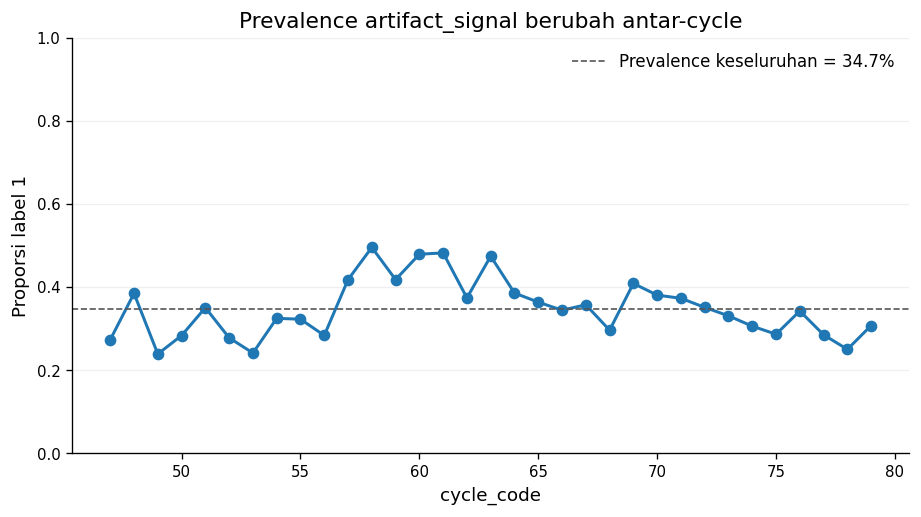

In [3]:
cycle_summary = (
    train.groupby("cycle_code", as_index=False)
    .agg(rows=("artifact_signal", "size"), positive_rate=("artifact_signal", "mean"))
)
fig, ax = plt.subplots()
ax.plot(cycle_summary.cycle_code, cycle_summary.positive_rate, marker="o", linewidth=1.8, color="#1f77b4")
ax.axhline(train.artifact_signal.mean(), color="#555555", linestyle="--", linewidth=1,
           label=f"Prevalence keseluruhan = {train.artifact_signal.mean():.1%}")
ax.set(title="Prevalence artifact_signal berubah antar-cycle", xlabel="cycle_code", ylabel="Proporsi label 1")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
early_cycles = cycle_summary.head(3).set_index("cycle_code").add_prefix("awal_")
late_cycles = cycle_summary.tail(3).set_index("cycle_code").add_prefix("akhir_")
display(pd.concat([early_cycles, late_cycles], axis=1))
plt.show()


## 3. EDA individual: teks kosong dan terisi

**Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?**

Sumber: official Classification Train.

### EDA 1. Data dan metode

Teks **kosong** berarti null, string kosong, atau hanya spasi. Waktu memakai `cycle_code`; volume memakai `text_load`, bukan jumlah token.

Perbandingan disesuaikan dengan memberi bobot yang sama pada kelompok waktu/volume untuk kedua status. Bobot mengikuti jumlah baris pada kelompok yang didukung. Minimum **20 baris per status per kelompok**. Rentang volume memakai kuantil tanpa label; ini penyesuaian kasar, bukan pencocokan nilai persis.

In [4]:
# Inline implementation from src/eda/availability.py; source SHA-256 2240da85704003ebeeb36b147ac01181f8f45da4e030af31c6cc7368dc2273d1.
"""Descriptive analysis helpers for Classification stream availability.

All contrasts are descriptive. Quantile boundaries are computed from
``text_load`` only; neither availability nor the outcome determines bins.
"""

from itertools import product
from typing import Iterable

import numpy as np
import pandas as pd

AVAILABILITY_ORDER = ("present", "missing")
PERIODS = ((47, 57, "47–57"), (58, 68, "58–68"), (69, 79, "69–79"))


def wilson_interval(successes: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    """Return a Wilson 95% interval for one binomial proportion."""
    if n <= 0 or successes < 0 or successes > n:
        raise ValueError("Wilson interval requires 0 <= successes <= n and n > 0")
    p = successes / n
    denominator = 1.0 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return float(max(0.0, center - half_width)), float(min(1.0, center + half_width))


def prepare_availability_frame(
    train: pd.DataFrame,
    stream_missing: Iterable[bool],
) -> pd.DataFrame:
    """Validate official raw columns and create a small analysis-only frame."""
    required = {"record_id", "cycle_code", "signal_stream", "text_load", "artifact_signal"}
    missing_columns = sorted(required - set(train.columns))
    if missing_columns:
        raise ValueError(f"Official Classification Train lacks columns: {missing_columns}")
    mask = np.asarray(list(stream_missing), dtype=bool)
    if len(mask) != len(train):
        raise ValueError("stream_missing must have one value per training row")
    if train["record_id"].isna().any() or train["record_id"].duplicated().any():
        raise ValueError("record_id must be complete and unique")
    target = pd.to_numeric(train["artifact_signal"], errors="raise")
    if target.isna().any() or not target.isin([0, 1]).all():
        raise ValueError("artifact_signal must be complete binary 0/1")
    cycle = pd.to_numeric(train["cycle_code"], errors="raise")
    if cycle.isna().any() or not np.equal(cycle, np.floor(cycle)).all():
        raise ValueError("cycle_code must be complete integer values")
    text_load = pd.to_numeric(train["text_load"], errors="raise")
    if text_load.isna().any() or not np.isfinite(text_load).all():
        raise ValueError("text_load must be complete and finite")

    period_labels = np.select(
        [cycle.between(start, end) for start, end, _ in PERIODS],
        [label for _, _, label in PERIODS],
        default="outside expected cycles",
    )
    if np.any(period_labels == "outside expected cycles"):
        raise ValueError("Train contains cycle_code outside the documented periods 47–79")
    return pd.DataFrame(
        {
            "record_id": train["record_id"].to_numpy(),
            "cycle_code": cycle.astype(int).to_numpy(),
            "period": period_labels,
            "text_load": text_load.astype(float).to_numpy(),
            "artifact_signal": target.astype(int).to_numpy(),
            "availability": np.where(mask, "missing", "present"),
        },
        index=train.index,
    )


def prevalence_table(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    """Return denominators, positive counts, and proportions by requested groups."""
    if not group_columns:
        raise ValueError("At least one grouping column is required")
    grouped = (
        frame.groupby(group_columns, observed=True, dropna=False)
        .agg(n=("artifact_signal", "size"), positive=("artifact_signal", "sum"))
        .reset_index()
    )
    grouped["prevalence"] = grouped["positive"] / grouped["n"]
    return grouped


def add_global_quantile_bins(frame: pd.DataFrame, q: int) -> tuple[pd.DataFrame, np.ndarray]:
    """Add global, outcome-blind quantile bins of text_load and return edges."""
    if q < 2:
        raise ValueError("q must be at least 2")
    if frame["text_load"].isna().any():
        raise ValueError("text_load cannot be missing when creating bins")
    labels, edges = pd.qcut(frame["text_load"], q=q, labels=False, retbins=True, duplicates="raise")
    result = frame.copy()
    result[f"text_load_q{q}"] = labels.astype(int)
    return result, np.asarray(edges, dtype=float)


def standardized_contrast(
    frame: pd.DataFrame,
    strata: list[str],
    *,
    min_support: int = 20,
    availability_column: str = "availability",
    outcome_column: str = "artifact_signal",
) -> tuple[dict, pd.DataFrame]:
    """Standardize both availability rates to the same pooled supported-cell mix.

    Cells qualify only if both availability groups have at least ``min_support``
    observations. A common cell weight is its combined denominator divided by
    all rows in supported cells. The returned summary keeps group-specific
    support and coverage denominators explicit.
    """
    if not strata or min_support < 1:
        raise ValueError("strata must be non-empty and min_support positive")
    needed = set(strata) | {availability_column, outcome_column}
    if needed - set(frame.columns):
        raise ValueError(f"Missing columns for standardization: {sorted(needed - set(frame.columns))}")
    if frame[list(strata) + [availability_column, outcome_column]].isna().any().any():
        raise ValueError("strata, availability, and outcome must be complete")
    if not frame[availability_column].isin(AVAILABILITY_ORDER).all():
        raise ValueError("availability values must be 'present' or 'missing'")
    if not frame[outcome_column].isin([0, 1]).all():
        raise ValueError("outcome must be binary 0/1")

    aggregation = (
        frame.groupby(strata + [availability_column], observed=True, dropna=False)[outcome_column]
        .agg(n="size", positive="sum")
        .reset_index()
    )
    domains = []
    for column in strata:
        values = list(pd.unique(frame[column]))
        try:
            values = sorted(values)
        except TypeError:
            pass
        domains.append(values)
    # Build lookup without relying on pandas' namedtuple field behavior for
    # arbitrary column names such as a caller-provided stratum label.
    indexed = {}
    for _, row in aggregation.iterrows():
        key = tuple(row[column] for column in strata)
        indexed[(key, row[availability_column])] = (int(row["n"]), int(row["positive"]))

    rows = []
    for cell_key in product(*domains):
        cell = dict(zip(strata, cell_key))
        state = {}
        for availability in AVAILABILITY_ORDER:
            n, positive = indexed.get((cell_key, availability), (0, 0))
            state[availability] = {
                "n": n,
                "positive": positive,
                "prevalence": positive / n if n else np.nan,
            }
        combined_n = state["present"]["n"] + state["missing"]["n"]
        supported = all(state[name]["n"] >= min_support for name in AVAILABILITY_ORDER)
        rows.append(
            {
                **cell,
                "n_present": state["present"]["n"],
                "positive_present": state["present"]["positive"],
                "prevalence_present": state["present"]["prevalence"],
                "n_missing": state["missing"]["n"],
                "positive_missing": state["missing"]["positive"],
                "prevalence_missing": state["missing"]["prevalence"],
                "combined_n": combined_n,
                "supported": supported,
            }
        )
    cells = pd.DataFrame(rows)
    supported = cells.loc[cells["supported"]].copy()
    if supported.empty:
        raise ValueError("No strata meet minimum support for both availability groups")
    supported_rows = int(supported["combined_n"].sum())
    weighted = {}
    for availability in AVAILABILITY_ORDER:
        weighted[availability] = float(
            np.sum(
                (supported["combined_n"] / supported_rows)
                * supported[f"prevalence_{availability}"].to_numpy(dtype=float)
            )
        )
    total_by_group = {
        name: int(frame[availability_column].eq(name).sum()) for name in AVAILABILITY_ORDER
    }
    covered_by_group = {
        "present": int(supported["n_present"].sum()),
        "missing": int(supported["n_missing"].sum()),
    }
    summary = {
        "strata": strata,
        "minimum_n_per_availability_per_cell": int(min_support),
        "cells_total": int(len(cells)),
        "cells_supported": int(supported.shape[0]),
        "supported_rows_total": supported_rows,
        "coverage_all_rows": float(supported_rows / len(frame)),
        "covered_rows_by_availability": covered_by_group,
        "total_rows_by_availability": total_by_group,
        "coverage_by_availability": {
            name: float(covered_by_group[name] / total_by_group[name])
            for name in AVAILABILITY_ORDER
        },
        "standardized_prevalence": weighted,
        "standardized_missing_minus_present_pp": float(100 * (weighted["missing"] - weighted["present"])),
        "standardization_weight": "combined cell n divided by all rows in supported cells; same weights for both groups",
        "support_rule": "each supported cell has at least min_support rows in both availability groups",
    }
    return summary, cells


In [5]:
eda_train = train
eda_analysis = prepare_availability_frame(
    eda_train, stream_missing_mask(eda_train["signal_stream"])
)
assert len(eda_analysis) == len(eda_train)
assert set(eda_analysis["availability"].unique()) == {"present", "missing"}
assert eda_analysis["cycle_code"].min() == 47
assert eda_analysis["cycle_code"].max() == 79
eda_COLORS = {"present": "#1f4e79", "missing": "#d17a22"}
print(
    f"Source: official Classification Train | {len(eda_train):,} rows x "
    f"{eda_train.shape[1]} columns | cycles 47-79"
)


Source: official Classification Train | 50,608 rows x 19 columns | cycles 47-79


### EDA 2. Gambaran data

In [6]:
eda_grouped = prevalence_table(eda_analysis, ['availability']).set_index('availability').loc[['present', 'missing']]
eda_overview = pd.DataFrame({'Baris (n)': eda_grouped['n'].astype(int), 'artifact_signal = 1 (n)': eda_grouped['positive'].astype(int), 'Proporsi artifact (%)': eda_grouped['prevalence'] * 100, 'text_load median': eda_analysis.groupby('availability')['text_load'].median().loc[['present', 'missing']], 'text_load Q1': eda_analysis.groupby('availability')['text_load'].quantile(0.25).loc[['present', 'missing']], 'text_load Q3': eda_analysis.groupby('availability')['text_load'].quantile(0.75).loc[['present', 'missing']]})
eda_overview.index.name = 'Availability'
display(eda_overview.round(2))
print(f'Total Train {len(eda_analysis):,}; label positif {eda_analysis.artifact_signal.sum():,} ({eda_analysis.artifact_signal.mean():.2%}); cycle unik {eda_analysis.cycle_code.nunique()}.')


,Baris (n),artifact_signal = 1 (n),Proporsi artifact (%),text_load median,text_load Q1,text_load Q3
Availability,,,,,,
present,47204,16272,34.47,31.78,27.70,36.92
missing,3404,1298,38.13,21.81,20.55,23.79


Total Train 50,608; label positif 17,570 (34.72%); cycle unik 33.


Teks kosong hanya mencakup 6,73% laporan. Ukuran kelompok yang jauh berbeda perlu diperhatikan saat membaca persentase dan ketidakpastiannya.

### EDA 3. Perbandingan awal

Error bar adalah interval Wilson 95% masing-masing kelompok, bukan interval selisihnya.

,Ketersediaan,artifact_signal = 1 (n),Denominator (n),Proporsi (%),Wilson 95% bawah (%),Wilson 95% atas (%)
0,present,16272,47204,34.47,34.04,34.90
1,missing,1298,3404,38.13,36.51,39.78


Proporsi artifact pada Train adalah **34.47%** saat stream tersedia dan **38.13%** saat missing. Selisih missing − present adalah **+3.66 poin persentase (pp)**.

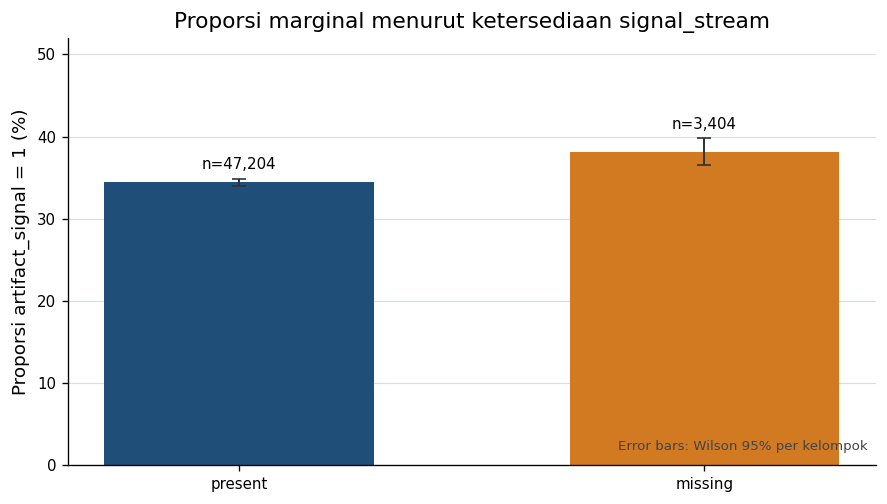

In [7]:
eda_marginal_rows = []
for eda_availability in ('present', 'missing'):
    eda_part = eda_analysis.loc[eda_analysis.availability.eq(eda_availability)]
    eda_successes, eda_n = (int(eda_part.artifact_signal.sum()), int(len(eda_part)))
    eda_low, eda_high = wilson_interval(eda_successes, eda_n)
    eda_marginal_rows.append({'Ketersediaan': eda_availability, 'artifact_signal = 1 (n)': eda_successes, 'Denominator (n)': eda_n, 'Proporsi (%)': 100 * eda_successes / eda_n, 'Wilson 95% bawah (%)': 100 * eda_low, 'Wilson 95% atas (%)': 100 * eda_high})
eda_marginal = pd.DataFrame(eda_marginal_rows)
eda_marginal_indexed = eda_marginal.set_index('Ketersediaan')
eda_marginal_gap_pp = eda_marginal_indexed.loc['missing', 'Proporsi (%)'] - eda_marginal_indexed.loc['present', 'Proporsi (%)']
display(eda_marginal.round(2))
display(Markdown(f"Proporsi artifact pada Train adalah **{eda_marginal_indexed.loc['present', 'Proporsi (%)']:.2f}%** saat stream tersedia dan **{eda_marginal_indexed.loc['missing', 'Proporsi (%)']:.2f}%** saat missing. Selisih missing − present adalah **{eda_marginal_gap_pp:+.2f} poin persentase (pp)**."))
eda_fig, eda_ax = plt.subplots(figsize=(7.5, 4.3))
eda_x = np.arange(len(eda_marginal))
eda_rates = eda_marginal['Proporsi (%)'].to_numpy()
eda_lower = eda_rates - eda_marginal['Wilson 95% bawah (%)'].to_numpy()
eda_upper = eda_marginal['Wilson 95% atas (%)'].to_numpy() - eda_rates
eda_ax.bar(eda_x, eda_rates, color=[eda_COLORS[eda_name] for eda_name in eda_marginal['Ketersediaan']], width=0.58, zorder=2)
eda_ax.errorbar(eda_x, eda_rates, yerr=np.vstack([eda_lower, eda_upper]), fmt='none', ecolor='#30343b', capsize=4, lw=1.2, zorder=3)
for eda_i, eda_row in eda_marginal.iterrows():
    eda_ax.text(eda_i, eda_row['Wilson 95% atas (%)'] + 1.2, f"n={int(eda_row['Denominator (n)']):,}", ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_marginal['Ketersediaan'])
eda_ax.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax.set_title('Proporsi marginal menurut ketersediaan signal_stream')
eda_ax.set_ylim(0, 52)
eda_ax.grid(axis='y', color='#d9dde3', linewidth=0.7, zorder=0)
eda_ax.text(0.99, 0.03, 'Error bars: Wilson 95% per kelompok', transform=eda_ax.transAxes, ha='right', va='bottom', fontsize=8, color='#40444b')
eda_fig.tight_layout()
plt.show()


Label 1 lebih sering muncul pada kelompok kosong, dengan selisih +3,66 pp. Ini belum memperhitungkan perbedaan waktu dan volume laporan.

### EDA 4. Perubahan sepanjang waktu

,Present n,Present (%),Missing n,Missing (%),Gap missing − present (pp)
period,,,,,
47–57,12537,30.78,1009,28.94,-1.84
58–68,15664,40.37,1072,50.37,10.01
69–79,19003,32.05,1323,35.22,3.18


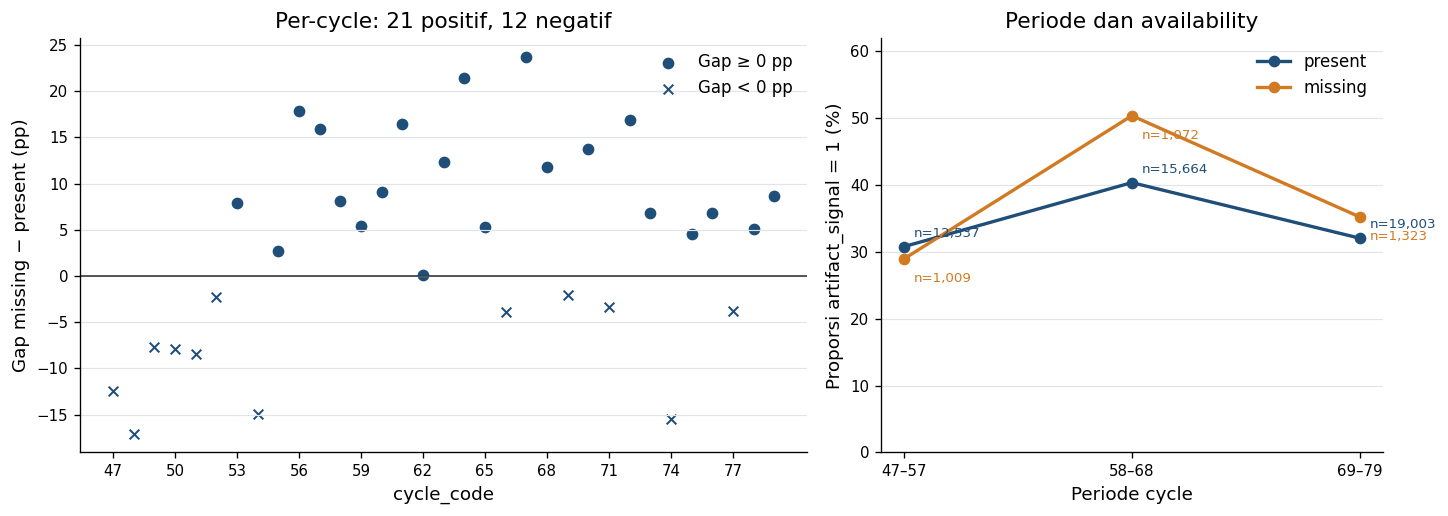

Gap per periode ialah **-1.84 pp**, **+10.01 pp**, dan **+3.18 pp**. Pada cycle dengan n≥20 untuk masing-masing status, 21/33 gap positif dan 12/33 negatif; rentangnya -17.04 sampai +23.73 pp.

In [8]:
eda_period_prevalence = prevalence_table(eda_analysis, ['period', 'availability'])
eda_period_pivot = eda_period_prevalence.pivot(index='period', columns='availability', values='prevalence').loc[['47–57', '58–68', '69–79']]
eda_period_n = eda_period_prevalence.pivot(index='period', columns='availability', values='n').loc[eda_period_pivot.index]
eda_period_summary = pd.DataFrame({'Present n': eda_period_n['present'].astype(int), 'Present (%)': 100 * eda_period_pivot['present'], 'Missing n': eda_period_n['missing'].astype(int), 'Missing (%)': 100 * eda_period_pivot['missing'], 'Gap missing − present (pp)': 100 * (eda_period_pivot['missing'] - eda_period_pivot['present'])})
display(eda_period_summary.round(2))
eda_cycle_prevalence = prevalence_table(eda_analysis, ['cycle_code', 'availability'])
eda_cycle_rates = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='prevalence')
eda_cycle_n = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='n')
eda_cycle_gap = 100 * (eda_cycle_rates['missing'] - eda_cycle_rates['present'])
eda_cycle_supported = eda_cycle_n['missing'].ge(20) & eda_cycle_n['present'].ge(20)
assert eda_cycle_supported.all(), 'Exact-cycle graph must not include unsupported groups'
eda_positive_cycles = int((eda_cycle_gap > 0).sum())
eda_negative_cycles = int((eda_cycle_gap < 0).sum())
eda_fig, (eda_ax_cycle, eda_ax_period) = plt.subplots(1, 2, figsize=(12.2, 4.4), gridspec_kw={'width_ratios': [1.45, 1]})
for eda_marker, eda_condition, eda_label in [('o', eda_cycle_gap >= 0, 'Gap ≥ 0 pp'), ('x', eda_cycle_gap < 0, 'Gap < 0 pp')]:
    eda_ax_cycle.scatter(eda_cycle_gap.index[eda_condition], eda_cycle_gap.loc[eda_condition], marker=eda_marker, s=34, color=eda_COLORS['present'], label=eda_label, linewidths=1.2)
eda_ax_cycle.axhline(0, color='#343a40', lw=1)
eda_ax_cycle.set_xticks(np.arange(47, 80, 3))
eda_ax_cycle.set_xlabel('cycle_code')
eda_ax_cycle.set_ylabel('Gap missing − present (pp)')
eda_ax_cycle.set_title(f'Per-cycle: {eda_positive_cycles} positif, {eda_negative_cycles} negatif')
eda_ax_cycle.legend(frameon=False, loc='best')
eda_ax_cycle.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_period_x = np.arange(len(eda_period_pivot))
for eda_availability in ('present', 'missing'):
    eda_values = 100 * eda_period_pivot[eda_availability].to_numpy()
    eda_ax_period.plot(eda_period_x, eda_values, marker='o', lw=2, color=eda_COLORS[eda_availability], label=eda_availability)
    for eda_j, (eda_value, eda_n) in enumerate(zip(eda_values, eda_period_n[eda_availability].to_numpy())):
        eda_offset = (6, 6) if eda_availability == 'present' else (6, -14)
        eda_ax_period.annotate(f'n={int(eda_n):,}', (eda_j, eda_value), xytext=eda_offset, textcoords='offset points', fontsize=8, color=eda_COLORS[eda_availability])
eda_ax_period.set_xticks(eda_period_x, eda_period_pivot.index)
eda_ax_period.set_xlabel('Periode cycle')
eda_ax_period.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax_period.set_title('Periode dan availability')
eda_ax_period.set_ylim(0, 62)
eda_ax_period.legend(frameon=False)
eda_ax_period.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Gap per periode ialah **{eda_period_summary.iloc[0]['Gap missing − present (pp)']:+.2f} pp**, **{eda_period_summary.iloc[1]['Gap missing − present (pp)']:+.2f} pp**, dan **{eda_period_summary.iloc[2]['Gap missing − present (pp)']:+.2f} pp**. Pada cycle dengan n≥20 untuk masing-masing status, {eda_positive_cycles}/{len(eda_cycle_gap)} gap positif dan {eda_negative_cycles}/{len(eda_cycle_gap)} negatif; rentangnya {eda_cycle_gap.min():+.2f} sampai {eda_cycle_gap.max():+.2f} pp."))


Gap positif pada 21 dari 33 cycle, tetapi negatif pada 12 lainnya. Periode tengah menunjukkan perbedaan terbesar; satu angka agregat menyembunyikan variasi ini.

### EDA 5. Perbedaan volume

,n,minimum,q1,median,q3,maximum
availability,,,,,,
present,47204,20.65,27.70,31.78,36.92,98.06
missing,3404,16.34,20.55,21.81,23.79,77.52


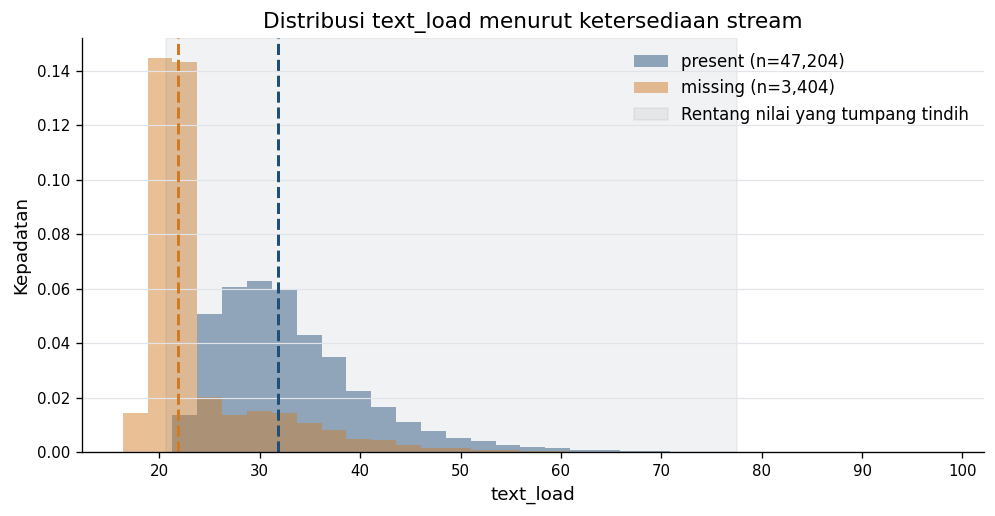

Median text_load adalah **31.78** saat stream tersedia dan **21.81** saat missing. Rentang nilai yang sama-sama teramati adalah **20.65–77.52**; di luarnya terdapat 906 baris missing dan 65 baris present.

In [9]:
eda_text_summary = eda_analysis.groupby('availability')['text_load'].agg(n='size', minimum='min', q1=lambda eda_x: eda_x.quantile(0.25), median='median', q3=lambda eda_x: eda_x.quantile(0.75), maximum='max').loc[['present', 'missing']]
eda_overlap_low = max(eda_text_summary.loc['present', 'minimum'], eda_text_summary.loc['missing', 'minimum'])
eda_overlap_high = min(eda_text_summary.loc['present', 'maximum'], eda_text_summary.loc['missing', 'maximum'])
eda_outside_missing = int((eda_analysis.availability.eq('missing') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
eda_outside_present = int((eda_analysis.availability.eq('present') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
display(eda_text_summary.round(2))
eda_fig, eda_ax = plt.subplots(figsize=(8.4, 4.4))
eda_bins = np.linspace(eda_analysis.text_load.min(), eda_analysis.text_load.max(), 34)
for eda_availability in ('present', 'missing'):
    eda_values = eda_analysis.loc[eda_analysis.availability.eq(eda_availability), 'text_load']
    eda_ax.hist(eda_values, bins=eda_bins, density=True, alpha=0.48, color=eda_COLORS[eda_availability], label=f'{eda_availability} (n={len(eda_values):,})')
    eda_ax.axvline(eda_values.median(), color=eda_COLORS[eda_availability], lw=1.8, linestyle='--')
eda_ax.axvspan(eda_overlap_low, eda_overlap_high, color='#78828f', alpha=0.1, label='Rentang nilai yang tumpang tindih')
eda_ax.set_xlabel('text_load')
eda_ax.set_ylabel('Kepadatan')
eda_ax.set_title('Distribusi text_load menurut ketersediaan stream')
eda_ax.legend(frameon=False)
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Median text_load adalah **{eda_text_summary.loc['present', 'median']:.2f}** saat stream tersedia dan **{eda_text_summary.loc['missing', 'median']:.2f}** saat missing. Rentang nilai yang sama-sama teramati adalah **{eda_overlap_low:.2f}–{eda_overlap_high:.2f}**; di luarnya terdapat {eda_outside_missing:,} baris missing dan {eda_outside_present:,} baris present."))


Median `text_load` kelompok kosong 21,81, sedangkan kelompok terisi 31,78. Komposisi volume yang berbeda menjadi alasan untuk membandingkan kelompok waktu/volume yang lebih setara.

### EDA 6. Menyamakan komposisi

Bandingkan hasil awal dengan penyesuaian setiap cycle serta tiga periode x 5/10 kelompok volume. **Gap = persentase kosong - terisi**, dalam poin persentase (pp). Coverage menunjukkan bagian data yang memenuhi minimum support.

In [10]:
eda_cycle_standardized, eda_cycle_cells = standardized_contrast(eda_analysis, ['cycle_code'], min_support=20)
eda_q5_frame, eda_q5_edges = add_global_quantile_bins(eda_analysis, 5)
eda_period_q5, eda_period_q5_cells = standardized_contrast(eda_q5_frame, ['period', 'text_load_q5'], min_support=20)
eda_q10_frame, eda_q10_edges = add_global_quantile_bins(eda_analysis, 10)
eda_period_q10, eda_period_q10_cells = standardized_contrast(eda_q10_frame, ['period', 'text_load_q10'], min_support=20)
eda_comparison_rows = [{'Kontras': 'Marginal (seluruh Train)', 'Present (%)': eda_marginal_indexed.loc['present', 'Proporsi (%)'], 'Missing (%)': eda_marginal_indexed.loc['missing', 'Proporsi (%)'], 'Gap missing − present (pp)': eda_marginal_gap_pp, 'Sel didukung': '—', 'Baris present tercakup': int(eda_analysis.availability.eq('present').sum()), 'Baris missing tercakup': int(eda_analysis.availability.eq('missing').sum()), 'Coverage keseluruhan (%)': 100.0}]
for eda_label, eda_result in [('Exact cycle', eda_cycle_standardized), ('Periode × kuantil text_load (5)', eda_period_q5), ('Periode × kuantil text_load (10)', eda_period_q10)]:
    eda_comparison_rows.append({'Kontras': eda_label, 'Present (%)': 100 * eda_result['standardized_prevalence']['present'], 'Missing (%)': 100 * eda_result['standardized_prevalence']['missing'], 'Gap missing − present (pp)': eda_result['standardized_missing_minus_present_pp'], 'Sel didukung': f"{eda_result['cells_supported']}/{eda_result['cells_total']}", 'Baris present tercakup': eda_result['covered_rows_by_availability']['present'], 'Baris missing tercakup': eda_result['covered_rows_by_availability']['missing'], 'Coverage keseluruhan (%)': 100 * eda_result['coverage_all_rows']})
eda_contrasts = pd.DataFrame(eda_comparison_rows)
display(eda_contrasts.round(2))
eda_support_by_group = pd.DataFrame([{'Kontras': 'Exact cycle', 'Coverage present (%)': 100 * eda_cycle_standardized['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_cycle_standardized['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 5', 'Coverage present (%)': 100 * eda_period_q5['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q5['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 10', 'Coverage present (%)': 100 * eda_period_q10['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q10['coverage_by_availability']['missing']}])
display(eda_support_by_group.round(2))
print(f'Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin={len(eda_q5_edges) - 1}; 10-bin={len(eda_q10_edges) - 1}.')


,Kontras,Present (%),Missing (%),Gap missing − present (pp),Sel didukung,Baris present tercakup,Baris missing tercakup,Coverage keseluruhan (%)
0,Marginal (seluruh Train),34.47,38.13,3.66,—,47204,3404,100.00
1,Exact cycle,34.47,38.43,3.96,33/33,47204,3404,100.00
2,Periode × kuantil text_load (5),35.17,32.87,-2.30,15/15,47204,3404,100.00
3,Periode × kuantil text_load (10),35.52,33.36,-2.15,28/30,44368,3372,94.33


,Kontras,Coverage present (%),Coverage missing (%)
0,Exact cycle,100.00,100.00
1,Periode × kuantil 5,100.00,100.00
2,Periode × kuantil 10,93.99,99.06


Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin=5; 10-bin=10.


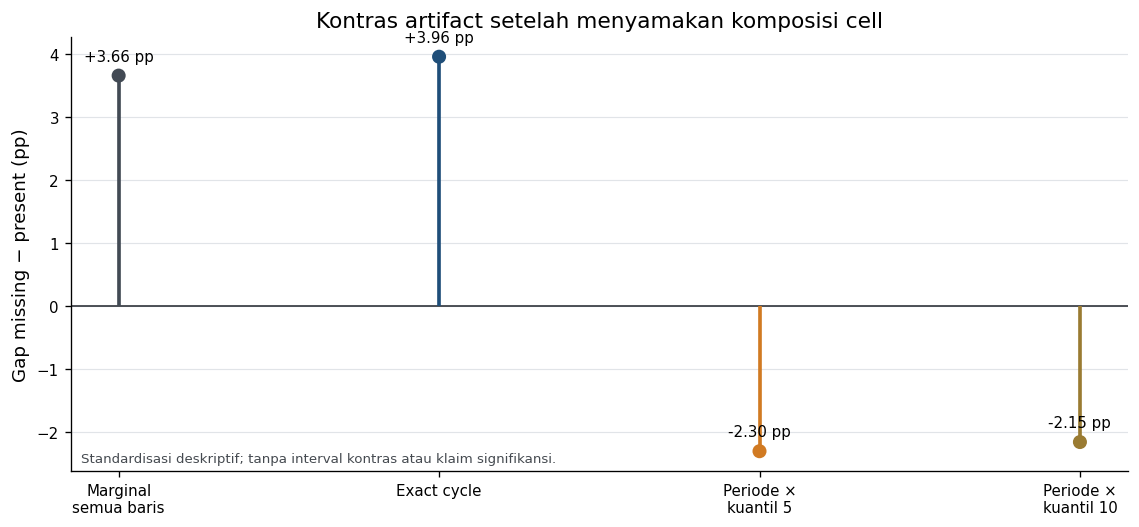

In [11]:
eda_fig, eda_ax = plt.subplots(figsize=(9.6, 4.5))
eda_labels = ['Marginal\nsemua baris', 'Exact cycle', 'Periode ×\nkuantil 5', 'Periode ×\nkuantil 10']
eda_gaps = eda_contrasts['Gap missing − present (pp)'].to_numpy()
eda_colors = ['#424a54', '#1f4e79', '#d17a22', '#9a7b32']
eda_x = np.arange(len(eda_gaps))
eda_ax.axhline(0, color='#30343b', lw=1)
eda_ax.vlines(eda_x, 0, eda_gaps, color=eda_colors, lw=2.2)
eda_ax.scatter(eda_x, eda_gaps, color=eda_colors, s=55, zorder=3)
for eda_i, eda_row in eda_contrasts.iterrows():
    eda_value = eda_row['Gap missing − present (pp)']
    eda_ax.annotate(f'{eda_value:+.2f} pp', (eda_i, eda_value), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_labels)
eda_ax.set_ylabel('Gap missing − present (pp)')
eda_ax.set_title('Kontras artifact setelah menyamakan komposisi cell')
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_ax.text(0.01, 0.02, 'Standardisasi deskriptif; tanpa interval kontras atau klaim signifikansi.', transform=eda_ax.transAxes, fontsize=8, color='#454a50')
eda_fig.tight_layout()
plt.show()


Menyamakan cycle saja tidak membalik arah gap, sedangkan penyesuaian periode dan volume membalikkannya. Hasil 5 dan 10 kelompok memiliki arah serupa, dengan coverage lebih rendah pada 10 kelompok.

### EDA 7. Interpretasi dan batasan

In [12]:
display(Markdown('\n\n'.join([
    f"Gap awal {eda_marginal_gap_pp:+.2f} pp; setelah penyesuaian cycle {eda_cycle_standardized['standardized_missing_minus_present_pp']:+.2f} pp; periode dan volume {eda_period_q5['standardized_missing_minus_present_pp']:+.2f} pp (5 kelompok) dan {eda_period_q10['standardized_missing_minus_present_pp']:+.2f} pp (10 kelompok).",
    f"Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup {eda_period_q10['supported_rows_total']:,}/{len(eda_analysis):,} baris ({eda_period_q10['coverage_all_rows']:.2%}); {eda_period_q10['cells_supported']}/{eda_period_q10['cells_total']} kelompok didukung.",
    "Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa."
])))


Gap awal +3.66 pp; setelah penyesuaian cycle +3.96 pp; periode dan volume -2.30 pp (5 kelompok) dan -2.15 pp (10 kelompok).

Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup 47,740/50,608 baris (94.33%); 28/30 kelompok didukung.

Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa.

### EDA 8. Kesimpulan

Ada perbedaan proporsi label, tetapi arahnya bergantung pada cara laporan dibandingkan. Pada seluruh data, teks kosong memiliki proporsi label 1 **38,13%**, dibanding **34,47%** pada teks terisi: gap **+3,66 pp**. Setelah komposisi setiap cycle disamakan, gap tetap positif **+3,96 pp** dengan seluruh **33 cycle dan 100% baris** didukung.

Ketika periode dan kelompok volume disamakan bersama, gap berbalik menjadi **-2,30 pp** pada 5 kelompok volume (**100% coverage**) dan **-2,15 pp** pada 10 kelompok (**94,33% coverage; 28/30 strata**). Jadi, pembalikan arah muncul pada penyesuaian gabungan waktu dan volume, bukan pada waktu saja.

Status teks kosong tidak cukup untuk menyimpulkan proporsi artifact tanpa memperhatikan komposisi laporan. Penyesuaian masih memakai rentang volume yang kasar; hasil ini bersifat deskriptif, tidak membuktikan sebab-akibat, dan belum memastikan pola yang sama pada Test.

## 4. Perkembangan pendekatan

Kode berikut hanya nama eksperimen, bukan algoritme baru. **HGB** adalah HistGradientBoosting, yaitu kumpulan pohon yang dilatih bertahap; **LR** adalah Logistic Regression.

| Nama yang dipakai | Kode riset | Fitur dan cara kerja |
|---|---|---|
| HGB terstruktur | C1_B | Fitur numerik/kategori, tanpa isi teks |
| LR gabungan | C2_B | Fitur terstruktur + TF-IDF teks |
| Routing | C4_HGB | LR gabungan saat teks terisi; HGB terstruktur saat kosong |

1. Majority dan model sederhana sebagai baseline.
2. LR/HGB dengan fitur terstruktur.
3. TF-IDF dan hybrid C2_B untuk menambah informasi teks.
4. C4_HGB mengatasi kelemahan hybrid saat teks kosong melalui routing.

Tabel berikut berasal dari eksperimen historis terverifikasi. Primary menggabungkan enam evaluasi dengan horizon 4 cycle; H12 memakai horizon 12 cycle. Sebagian barisnya sama, sehingga kedua hasil bukan bukti independen. TF-IDF memakai unigram-bigram, maksimal 20.000 fitur, `min_df=3`, dan sublinear TF.

### Asal hasil perbandingan

Tabel historis merangkum eksperimen sebelumnya dan disertakan langsung di notebook. Tabel ini menjadi pembanding; evaluasi temporal di bagian berikut tetap dilatih dan dihitung ulang dari data mentah.

,metode,Primary Macro F1,H12 Macro F1
recipe,,,
C0_A,Majority,0.38938,0.38938
C0_C,LR impact + EF,0.38938,0.38938
C1_A,LR structured,0.71453,0.67679
C1_B,HGB terstruktur,0.73102,0.68906
C2_A,TF-IDF LR,0.80139,0.78192
C2_B,LR gabungan,0.82063,0.78858
C4_HGB,Routing,0.82548,0.79681


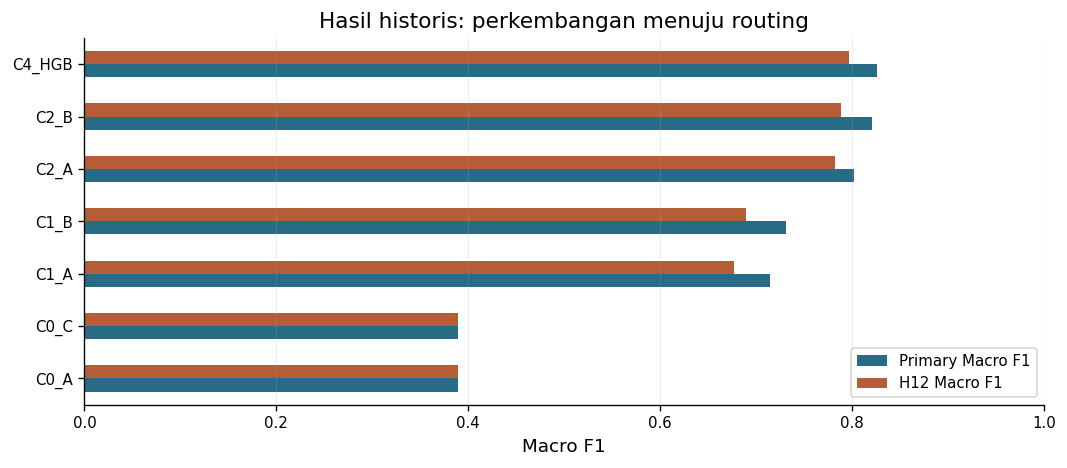

policy                  fixed_0.5  inner_pooled
recipe      family                             
LR gabungan H12 pooled     0.7886        0.7924
            Primary        0.8206        0.8188
Routing     H12 pooled     0.7968        0.7998
            Primary        0.8255        0.8236

,primary,H12,primary stream-present,primary stream-missing,H12 stream-present,H12 stream-missing
recipe,,,,,,
C2_B,0.8206,0.7886,0.8286,0.7104,0.8005,0.6305
C4_LR,0.8242,0.7945,0.8286,0.7596,0.8005,0.7085
C4_HGB,0.8255,0.7968,0.8286,0.7817,0.8005,0.7450


Historical Kaggle reference: {'status': 'COMPLETE', 'reference': 57808225, 'public_score': 0.82641, 'private_score': None}
Historical source SHA-256:
  experiments/classification_round1/protocol.json: cf2a129c5c6f555fb5d1f15d7ef65595abd4bb09a6913f55b4d96ac5cdfb6b80
  experiments/classification_round1/freeze.json: 9eb7a7156a8985aac815e17aead155604d669e20f22f1d51bacfae9f7f4f83c9
  experiments/classification_round2/freeze.json: f9887c960ecc9dd7aea20b9dcd9475ce30e8e2cab54c6af47665037e0198cf06
  reports/classification_round1/results.json: 3c2dc8d9a83d351e38eea3ea90da3b07fd4e037baa5d030ea16868db7ddfe666
  reports/classification_round2/results.json: 10bcbe0033b3a66a431bebf79ce5e9014b8cd4290e097228dd1eeada596e7414
  reports/classification_round1/fit_audits/fit75.json: 428a8f1530e0eadf288303721519e521ee9b14fc65bff84faf09aae5a08d4e2b
  reports/submissions/classification_initial_manifest.json: 3369ec1a73c98a276c65783bd2e71a3bdfc129cece8d48a035aee98846818974


In [13]:
HISTORICAL_W6_HASHES = {'C1_B': 'a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1cb708ddc208f613095',
 'C2_B': '01a886bb391728b58cb3504946d620efabc4859ea55585d36b76028793feb1f4',
 'C4_HGB': 'fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c0a793767733b9d1130'}
HISTORICAL_PROVENANCE = {'experiments/classification_round1/protocol.json': 'cf2a129c5c6f555fb5d1f15d7ef65595abd4bb09a6913f55b4d96ac5cdfb6b80',
 'experiments/classification_round1/freeze.json': '9eb7a7156a8985aac815e17aead155604d669e20f22f1d51bacfae9f7f4f83c9',
 'experiments/classification_round2/freeze.json': 'f9887c960ecc9dd7aea20b9dcd9475ce30e8e2cab54c6af47665037e0198cf06',
 'reports/classification_round1/results.json': '3c2dc8d9a83d351e38eea3ea90da3b07fd4e037baa5d030ea16868db7ddfe666',
 'reports/classification_round2/results.json': '10bcbe0033b3a66a431bebf79ce5e9014b8cd4290e097228dd1eeada596e7414',
 'reports/classification_round1/fit_audits/fit75.json': '428a8f1530e0eadf288303721519e521ee9b14fc65bff84faf09aae5a08d4e2b',
 'reports/submissions/classification_initial_manifest.json': '3369ec1a73c98a276c65783bd2e71a3bdfc129cece8d48a035aee98846818974'}
HISTORICAL_KAGGLE = {'status': 'COMPLETE',
 'reference': 57808225,
 'public_score': 0.82641,
 'private_score': None}
MODEL_LABELS = {'C0_A': 'Majority',
 'C0_C': 'LR impact + EF',
 'C1_A': 'LR structured',
 'C1_B': 'HGB terstruktur',
 'C2_A': 'TF-IDF LR',
 'C2_B': 'LR gabungan',
 'C4_HGB': 'Routing'}
historical_evolution = pd.DataFrame([{'recipe': 'C0_A',
  'metode': 'Majority',
  'Primary Macro F1': 0.38938207136640557,
  'H12 Macro F1': 0.38938207136640557},
 {'recipe': 'C0_C',
  'metode': 'LR impact + EF',
  'Primary Macro F1': 0.38938207136640557,
  'H12 Macro F1': 0.38938207136640557},
 {'recipe': 'C1_A',
  'metode': 'LR structured',
  'Primary Macro F1': 0.7145252653352889,
  'H12 Macro F1': 0.6767855702307287},
 {'recipe': 'C1_B',
  'metode': 'HGB terstruktur',
  'Primary Macro F1': 0.7310190201940008,
  'H12 Macro F1': 0.6890587156405323},
 {'recipe': 'C2_A',
  'metode': 'TF-IDF LR',
  'Primary Macro F1': 0.8013882844693636,
  'H12 Macro F1': 0.7819236858188459},
 {'recipe': 'C2_B',
  'metode': 'LR gabungan',
  'Primary Macro F1': 0.8206329781454547,
  'H12 Macro F1': 0.7885811256706727},
 {'recipe': 'C4_HGB',
  'metode': 'Routing',
  'Primary Macro F1': 0.8254807111314647,
  'H12 Macro F1': 0.7968102588689854}]).set_index("recipe")
display(historical_evolution.round(5))
ax = historical_evolution[["Primary Macro F1", "H12 Macro F1"]].plot.barh(
    color=["#276b86", "#b45d36"], figsize=(9, 4)
)
ax.set(
    title="Hasil historis: perkembangan menuju routing",
    xlabel="Macro F1",
    xlim=(0, 1),
    ylabel="",
)
ax.legend(fontsize=9)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

threshold_table = pd.DataFrame([{'recipe': 'LR gabungan',
  'family': 'Primary',
  'policy': 'fixed_0.5',
  'Macro F1': 0.8206329781454547},
 {'recipe': 'LR gabungan',
  'family': 'Primary',
  'policy': 'inner_pooled',
  'Macro F1': 0.8187574582171067},
 {'recipe': 'Routing',
  'family': 'Primary',
  'policy': 'fixed_0.5',
  'Macro F1': 0.8254807111314647},
 {'recipe': 'Routing',
  'family': 'Primary',
  'policy': 'inner_pooled',
  'Macro F1': 0.8236066688271738},
 {'recipe': 'LR gabungan',
  'family': 'H12 pooled',
  'policy': 'fixed_0.5',
  'Macro F1': 0.7885811256706727},
 {'recipe': 'LR gabungan',
  'family': 'H12 pooled',
  'policy': 'inner_pooled',
  'Macro F1': 0.7924027082959779},
 {'recipe': 'Routing',
  'family': 'H12 pooled',
  'policy': 'fixed_0.5',
  'Macro F1': 0.7968102588689854},
 {'recipe': 'Routing',
  'family': 'H12 pooled',
  'policy': 'inner_pooled',
  'Macro F1': 0.7998390469349026}])
display(
    threshold_table.pivot_table(
        index=["recipe", "family"], columns="policy", values="Macro F1"
    ).round(4)
)
display(pd.DataFrame([{'recipe': 'C2_B',
  'primary': 0.8206329781454547,
  'H12': 0.7885811256706727,
  'primary stream-present': 0.8285552807187074,
  'primary stream-missing': 0.7104270679715272,
  'H12 stream-present': 0.800474200237395,
  'H12 stream-missing': 0.6304593574930747},
 {'recipe': 'C4_LR',
  'primary': 0.8242080321167009,
  'H12': 0.7945131102741163,
  'primary stream-present': 0.8285552807187074,
  'primary stream-missing': 0.7596095298014476,
  'H12 stream-present': 0.800474200237395,
  'H12 stream-missing': 0.7085442884508135},
 {'recipe': 'C4_HGB',
  'primary': 0.8254807111314647,
  'H12': 0.7968102588689854,
  'primary stream-present': 0.8285552807187074,
  'primary stream-missing': 0.781711759145506,
  'H12 stream-present': 0.800474200237395,
  'H12 stream-missing': 0.7450062481396054}]).set_index("recipe").round(4))
print("Historical Kaggle reference:", HISTORICAL_KAGGLE)
print("Historical source SHA-256:")
for name, digest in HISTORICAL_PROVENANCE.items():
    print(f"  {name}: {digest}")


Model dua fitur dan majority masih lemah. Fitur structured menaikkan Macro F1 primary menjadi **0,7145 (LR)** dan **0,7310 (HGB)**; TF-IDF saja mencapai **0,8014**. Menggabungkan teks dan struktur pada LR gabungan (C2_B) mencapai **0,8206**, sehingga kedua jenis informasi saling melengkapi dalam eksperimen ini.

Namun LR gabungan (C2_B) lebih lemah pada teks kosong: Macro F1 subgroup **0,7104**, dibanding **0,7817** setelah memakai fallback HGB pada Routing (C4_HGB). Routing dipilih untuk menangani perbedaan tersebut sambil mempertahankan hybrid pada teks terisi. Hasil gabungan menjadi **0,8255 primary / 0,7968 H12**.

Pemilihan threshold dari inner history memperbaiki H12, tetapi menurunkan primary Routing (C4_HGB) dari **0,8255 menjadi 0,8236**. Karena manfaatnya tidak konsisten, keputusan tetap memakai threshold **0,50**.

## 5. Pipeline dan validasi temporal

Fit pada cycle 47-75, evaluasi 76-79. LR gabungan (C2_B) memakai structured + TF-IDF Logistic Regression dan HGB terstruktur (C1_B) memakai structured HGB. Imputasi, encoding, scaling, dan vocabulary hanya dipelajari dari fold fit.

### Preprocessing dan definisi model

Fungsi berikut menangani format numerik, nilai kosong, kategori, representasi teks, dan model. Semua parameter preprocessing dipelajari dari data training pada fold yang bersangkutan. Kode tersedia langsung di sel dan dapat dibuka untuk diperiksa.

In [14]:
import math
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

STRUCTURED_FEATURES = (
    "impact_load", "entry_friction", "cycle_code", "scope_pressure", "text_load",
    "scope_trace", "org_spread", "module_spread", "telemetry_flag",
    "org_code", "module_code", "pattern_code",
)
HYBRID_FEATURES = (*STRUCTURED_FEATURES, "signal_stream")
NUMERIC_FEATURES = (
    "impact_load", "entry_friction", "cycle_code", "scope_pressure", "text_load",
)
COUNT_FEATURES = ("scope_trace", "org_spread", "module_spread")
CATEGORY_FEATURES = ("org_code", "module_code", "pattern_code")
COUNT_TOKEN = re.compile(r"^\s*(?P<approx>~)?\s*(?P<number>\d+(?:\.\d+)?)\s*(?P<unit>.*?)\s*$")
TELEMETRY_MAP = {
    "inactive": 0.0, "false": 0.0, "n": 0.0, "0": 0.0,
    "active": 1.0, "true": 1.0, "y": 1.0, "1": 1.0,
}
HGB_PARAMETERS = {
    "loss": "log_loss", "learning_rate": 0.05, "max_iter": 200,
    "max_leaf_nodes": 15, "min_samples_leaf": 30, "l2_regularization": 1.0,
    "max_bins": 255, "early_stopping": False, "random_state": 42,
}
LR_PARAMETERS = {
    "C": 1.0, "solver": "liblinear", "max_iter": 2000,
    "tol": 1e-4, "class_weight": None, "random_state": 42,
}
TFIDF_PARAMETERS = {
    "ngram_range": (1, 2), "min_df": 3, "max_df": 0.995,
    "max_features": 20000, "sublinear_tf": True, "lowercase": True,
    "strip_accents": "unicode", "dtype": np.float64,
}


def is_missing(value):
    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


def number_parts(series):
    missing = series.map(is_missing).to_numpy(dtype=bool)
    blank = series.map(lambda value: isinstance(value, str) and not value.strip()).to_numpy(dtype=bool)
    missing |= blank
    values = pd.to_numeric(series.mask(missing), errors="coerce").to_numpy(dtype=float)
    finite = np.isfinite(values)
    invalid = (~missing) & (~finite)
    values[~finite] = np.nan
    return values, missing.astype(float), invalid.astype(float)


def count_parts(series):
    size = len(series)
    value = np.full(size, np.nan, dtype=float)
    approximate = np.zeros(size, dtype=float)
    suffix = np.zeros(size, dtype=float)
    parse_fail = np.zeros(size, dtype=float)
    missing = np.zeros(size, dtype=float)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        if is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[row] = 1.0
            continue
        match = COUNT_TOKEN.fullmatch(str(raw))
        if match is None:
            parse_fail[row] = 1.0
            continue
        unit = match.group("unit").strip().casefold()
        suffix[row] = float(bool(unit))
        if unit not in {"", "nodes"}:
            parse_fail[row] = 1.0
            continue
        parsed = float(match.group("number"))
        if not math.isfinite(parsed):
            parse_fail[row] = 1.0
            continue
        value[row] = parsed
        approximate[row] = float(match.group("approx") is not None)
    return value, approximate, suffix, parse_fail, missing


def telemetry_parts(series):
    value = np.full(len(series), np.nan, dtype=float)
    unknown = np.zeros(len(series), dtype=float)
    missing = np.zeros(len(series), dtype=float)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        if is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[row] = 1.0
            continue
        normalized = str(raw).strip().casefold()
        if normalized not in TELEMETRY_MAP:
            unknown[row] = 1.0
            continue
        value[row] = TELEMETRY_MAP[normalized]
    return value, unknown, missing


def category_values(series):
    values = np.empty(len(series), dtype=object)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        values[row] = np.nan if is_missing(raw) or (isinstance(raw, str) and not raw.strip()) else str(raw).strip()
    return values


def text_values(series):
    documents = []
    missing = np.zeros(len(series), dtype=bool)
    for row, raw in enumerate(series.to_numpy(dtype=object)):
        if is_missing(raw):
            documents.append("")
            missing[row] = True
        else:
            text = str(raw).strip()
            documents.append(text)
            missing[row] = not bool(text)
    return documents, missing


def stream_missing_mask(frame):
    series = frame["signal_stream"] if isinstance(frame, pd.DataFrame) else frame
    return text_values(series)[1]


class StructuredFeatures:
    """Fit-only numeric medians and native ordinal categories for C1_B/C2_B."""

    def __init__(self):
        self.encoder = None
        self.names = []
        self.categorical_positions = []
        self.medians = {}

    def _raw_matrix(self, frame, fit_categories):
        numeric_columns = []
        numeric_names = []
        raw_categories = {}
        category_missing = {}
        for feature in STRUCTURED_FEATURES:
            if feature in NUMERIC_FEATURES:
                values, missing, invalid = number_parts(frame[feature])
                numeric_columns.extend((values, invalid, missing))
                numeric_names.extend((feature, f"{feature}__parsefail", f"{feature}__missing"))
            elif feature in COUNT_FEATURES:
                values, approximate, suffix, invalid, missing = count_parts(frame[feature])
                numeric_columns.extend((values, approximate, suffix, invalid, missing))
                numeric_names.extend((
                    feature, f"{feature}__approximate", f"{feature}__suffix_present",
                    f"{feature}__parsefail", f"{feature}__missing",
                ))
            elif feature == "telemetry_flag":
                values, unknown, missing = telemetry_parts(frame[feature])
                numeric_columns.extend((values, unknown, missing))
                numeric_names.extend((feature, f"{feature}__unknown", f"{feature}__missing"))
            elif feature in CATEGORY_FEATURES:
                raw = category_values(frame[feature])
                raw_categories[feature] = raw
                category_missing[feature] = np.array(
                    [value is np.nan or is_missing(value) for value in raw], dtype=float
                )

        if fit_categories:
            self.encoder = OrdinalEncoder(
                min_frequency=30, max_categories=254,
                handle_unknown="use_encoded_value", unknown_value=-1,
                encoded_missing_value=-1, dtype=np.float64,
            )
            self.encoder.fit(np.column_stack([raw_categories[name] for name in CATEGORY_FEATURES]))
        encoded = self.encoder.transform(
            np.column_stack([raw_categories[name] for name in CATEGORY_FEATURES])
        )

        columns = []
        names = []
        categorical_positions = []
        numeric_index = 0
        category_index = 0
        for feature in STRUCTURED_FEATURES:
            if feature in NUMERIC_FEATURES:
                for _ in range(3):
                    columns.append(numeric_columns[numeric_index])
                    names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature in COUNT_FEATURES:
                for _ in range(5):
                    columns.append(numeric_columns[numeric_index])
                    names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature == "telemetry_flag":
                for _ in range(3):
                    columns.append(numeric_columns[numeric_index])
                    names.append(numeric_names[numeric_index])
                    numeric_index += 1
            else:
                categorical_positions.append(len(names))
                columns.append(encoded[:, category_index])
                names.append(f"{feature}__ordinal")
                columns.append(category_missing[feature])
                names.append(f"{feature}__missing")
                category_index += 1
        matrix = np.column_stack(columns).astype(float, copy=False)
        return matrix, names, raw_categories, category_missing, categorical_positions

    def fit_transform(self, frame):
        matrix, names, _, _, self.categorical_positions = self._raw_matrix(frame, fit_categories=True)
        self.names = names
        categorical = set(self.categorical_positions)
        self.medians = {}
        for position, name in enumerate(names):
            if position in categorical:
                continue
            column = matrix[:, position]
            finite = column[np.isfinite(column)]
            median = float(np.median(finite)) if len(finite) else 0.0
            self.medians[name] = median
            column[~np.isfinite(column)] = median
        mask = [position in categorical for position in range(len(names))]
        return matrix, mask

    def transform(self, frame):
        matrix, names, raw_categories, _, _ = self._raw_matrix(frame, fit_categories=False)
        if names != self.names:
            raise RuntimeError("Feature order changed after fit.")
        unknown = {}
        for index, name in enumerate(CATEGORY_FEATURES):
            seen = {
                str(value)
                for value in self.encoder.categories_[index]
                if not is_missing(value)
            }
            unknown[name] = int(
                sum(
                    not is_missing(value) and str(value) not in seen
                    for value in raw_categories[name]
                )
            )
        categorical = set(self.categorical_positions)
        for position, name in enumerate(names):
            if position in categorical:
                continue
            column = matrix[:, position]
            column[~np.isfinite(column)] = self.medians[name]
        return matrix, unknown

    def raw_categories(self, frame):
        return self._raw_matrix(frame, fit_categories=False)[2]


def category_tokens(raw_categories):
    tokens = np.empty((len(next(iter(raw_categories.values()))), len(raw_categories)), dtype=object)
    for column, name in enumerate(raw_categories):
        tokens[:, column] = [
            "M:" if is_missing(value) else "V:" + str(value)
            for value in raw_categories[name]
        ]
    return tokens


class ClassificationRecipe:
    """Only the two fitted recipes used by the C4_HGB routing decision."""

    def __init__(self, recipe_id):
        if recipe_id not in {"C1_B", "C2_B"}:
            raise ValueError("recipe_id must be C1_B or C2_B.")
        self.recipe_id = recipe_id
        self.features = list(STRUCTURED_FEATURES if recipe_id == "C1_B" else HYBRID_FEATURES)
        self.preprocessor = StructuredFeatures()
        self.estimator = None

    def _select(self, frame):
        if not isinstance(frame, pd.DataFrame) or frame.columns.has_duplicates:
            raise TypeError("Features must be a DataFrame with unique column names.")
        missing = [name for name in self.features if name not in frame.columns]
        if missing:
            raise ValueError(f"Missing required features: {missing}")
        return frame.loc[:, self.features]

    def fit(self, frame, target):
        selected = self._select(frame)
        target = np.asarray(target)
        if target.ndim != 1 or len(target) != len(selected) or not len(target):
            raise ValueError("Labels must be a nonempty vector aligned with rows.")
        numeric_target = target.astype(float)
        if not np.isfinite(numeric_target).all() or not np.isin(numeric_target, [0, 1]).all():
            raise ValueError("artifact_signal must be finite binary labels.")
        target = numeric_target.astype(np.int8)
        if not np.array_equal(np.unique(target), np.array([0, 1])):
            raise ValueError("Both classes must be present in the fit rows.")

        structured, categorical_mask = self.preprocessor.fit_transform(
            selected.loc[:, list(STRUCTURED_FEATURES)]
        )
        if self.recipe_id == "C1_B":
            self.estimator = HistGradientBoostingClassifier(
                **HGB_PARAMETERS, categorical_features=categorical_mask
            )
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                self.estimator.fit(structured, target)
            if any(issubclass(item.category, ConvergenceWarning) for item in caught):
                raise RuntimeError("C1_B HistGradientBoostingClassifier did not converge.")
            return self

        raw_categories = self.preprocessor.raw_categories(
            selected.loc[:, list(STRUCTURED_FEATURES)]
        )
        categorical_positions = set(self.preprocessor.categorical_positions)
        numeric_positions = [
            index for index in range(structured.shape[1])
            if index not in categorical_positions
        ]
        numeric = structured[:, numeric_positions].copy()
        self.scaler = StandardScaler()
        numeric = self.scaler.fit_transform(numeric)
        tokens = category_tokens(raw_categories)
        self.encoder = OneHotEncoder(
            min_frequency=30, max_categories=254,
            handle_unknown="infrequent_if_exist", sparse_output=True, dtype=np.float64,
        )
        categorical = self.encoder.fit_transform(tokens)
        design = sparse.hstack(
            (sparse.csr_matrix(numeric), categorical), format="csr", dtype=np.float64
        )

        documents, missing = text_values(selected["signal_stream"])
        if not any(documents):
            self.vectorizer = None
            text = sparse.csr_matrix((len(documents), 0), dtype=np.float64)
        else:
            self.vectorizer = TfidfVectorizer(**TFIDF_PARAMETERS)
            try:
                text = self.vectorizer.fit_transform(documents).tocsr()
            except ValueError as exc:
                message = str(exc).casefold()
                empty_vocabulary = (
                    "empty vocabulary", "after pruning, no terms remain",
                    "max_df corresponds to < documents than min_df",
                    "max_df corresponds to less documents than min_df",
                )
                if not any(marker in message for marker in empty_vocabulary):
                    raise
                self.vectorizer = None
                text = sparse.csr_matrix((len(documents), 0), dtype=np.float64)

        missing_column = sparse.csr_matrix(missing.astype(np.float64).reshape(-1, 1))
        design = sparse.hstack((design, text, missing_column), format="csr", dtype=np.float64)
        self.estimator = LogisticRegression(**LR_PARAMETERS)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            self.estimator.fit(design, target)
        if any(issubclass(item.category, ConvergenceWarning) for item in caught):
            raise RuntimeError("C2_B LogisticRegression did not converge.")
        return self

    def predict_proba(self, frame):
        selected = self._select(frame)
        if self.recipe_id == "C1_B":
            structured, _ = self.preprocessor.transform(
                selected.loc[:, list(STRUCTURED_FEATURES)]
            )
            probability = self.estimator.predict_proba(structured)[:, 1]
        else:
            structured, _ = self.preprocessor.transform(
                selected.loc[:, list(STRUCTURED_FEATURES)]
            )
            raw_categories = self.preprocessor.raw_categories(
                selected.loc[:, list(STRUCTURED_FEATURES)]
            )
            numeric_positions = [
                index for index in range(structured.shape[1])
                if index not in set(self.preprocessor.categorical_positions)
            ]
            numeric = self.scaler.transform(structured[:, numeric_positions])
            categorical = self.encoder.transform(category_tokens(raw_categories))
            design = sparse.hstack(
                (sparse.csr_matrix(numeric), categorical), format="csr", dtype=np.float64
            )
            documents, missing = text_values(selected["signal_stream"])
            if self.vectorizer is None:
                text = sparse.csr_matrix((len(documents), 0), dtype=np.float64)
            else:
                text = self.vectorizer.transform(documents).tocsr()
            missing_column = sparse.csr_matrix(missing.astype(np.float64).reshape(-1, 1))
            design = sparse.hstack((design, text, missing_column), format="csr", dtype=np.float64)
            probability = self.estimator.predict_proba(design)[:, 1]
        probability = np.asarray(probability, dtype=float)
        if probability.shape != (len(selected),) or not np.isfinite(probability).all():
            raise RuntimeError("Predicted probabilities are invalid.")
        if ((probability < 0) | (probability > 1)).any():
            raise RuntimeError("Probability outside [0, 1].")
        return probability


In [15]:
def binary_metrics(actual, probability, threshold=0.5):
    y = np.asarray(actual)
    p = np.asarray(probability, dtype=float)
    if y.ndim != 1 or p.shape != y.shape or not np.isin(y, [0, 1]).all():
        raise ValueError('Aligned binary labels and one-dimensional probabilities required.')
    if not np.isfinite(p).all() or not ((p >= 0) & (p <= 1)).all():
        raise ValueError('Finite probabilities in [0,1] required.')
    cut = np.asarray(threshold, dtype=float)
    if cut.ndim > 1 or (cut.ndim == 1 and cut.shape != p.shape) or not np.isfinite(cut).all() or not ((cut >= 0) & (cut <= 1)).all():
        raise ValueError('Invalid threshold.')
    prediction = (p >= cut).astype(int)
    cm = np.zeros((2, 2), dtype=int)
    np.add.at(cm, (y.astype(int), prediction), 1)
    support = cm.sum(axis=1)
    per_class = []
    for label in (0, 1):
        tp = int(cm[label, label])
        fp = int(cm[:, label].sum() - tp)
        fn = int(cm[label, :].sum() - tp)
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
        per_class.append({'label': label, 'support': int(support[label]),
                          'precision': precision, 'recall': recall, 'f1': f1})
    n = len(y)
    both = bool((support > 0).all())
    result = {'n': n, 'threshold': float(cut) if cut.ndim == 0 else None,
              'threshold_range': [float(cut.min()), float(cut.max())] if cut.size else None, 'label_order': [0, 1],
              'confusion_matrix': cm.tolist(), 'per_class': per_class,
              'macro_f1': float(np.mean([c['f1'] for c in per_class])) if n else None,
              'balanced_accuracy': float(np.mean([c['recall'] for c in per_class])) if both else None,
              'average_precision': float(average_precision_score(y, p)) if both else None,
              'positive_rate': float(y.mean()) if n else None,
              'positive_prediction_rate': float(prediction.mean()) if n else None,
              'mean_probability': float(p.mean()) if n else None,
              'brier_score': float(np.mean((p-y)**2)) if n else None,
              'false_positive': int(cm[0, 1]), 'false_negative': int(cm[1, 0]),
              'single_class_actual': bool(n and not both),
              'metric_convention': 'Fixed labels [0,1], undefined per-class precision/recall/F1=0; AP and balanced accuracy null without both actual classes.'}
    return result


### Pemeriksaan reproduksi

Imputasi, encoding, scaling, dan TF-IDF dipelajari di dalam fit. Hash prediksi dibandingkan dengan receipt historis W6 tanpa cache model pribadi.

In [16]:
FIT_CYCLES = (47, 75)
VALID_CYCLES = (76, 79)
fit_mask = train.cycle_code.between(*FIT_CYCLES)
valid_mask = train.cycle_code.between(*VALID_CYCLES)
fit_rows = np.flatnonzero(fit_mask.to_numpy())
valid_rows = np.flatnonzero(valid_mask.to_numpy())
assert not np.intersect1d(fit_rows, valid_rows).size
assert train.loc[fit_mask, "cycle_code"].max() < train.loc[valid_mask, "cycle_code"].min()

fit_frame = train.loc[fit_mask]
valid_frame = train.loc[valid_mask]
y_fit = fit_frame["artifact_signal"].to_numpy(dtype=np.int8, copy=True)
c2b = ClassificationRecipe("C2_B")
c1b = ClassificationRecipe("C1_B")
with threadpool_limits(limits=2):
    c2b.fit(fit_frame.loc[:, list(HYBRID_FEATURES)], y_fit)
    probability_c2b = c2b.predict_proba(valid_frame.loc[:, list(HYBRID_FEATURES)])
    c1b.fit(fit_frame.loc[:, list(STRUCTURED_FEATURES)], y_fit)
    probability_c1b = c1b.predict_proba(valid_frame.loc[:, list(STRUCTURED_FEATURES)])

missing_valid = stream_missing_mask(valid_frame)
probability_c4hgb = np.where(missing_valid, probability_c1b, probability_c2b)
probabilities = {
    "C1_B": probability_c1b,
    "C2_B": probability_c2b,
    "C4_HGB": probability_c4hgb,
}
threshold = 0.50
y_valid = valid_frame["artifact_signal"].to_numpy(dtype=np.int8, copy=True)
validation_cycles = valid_frame["cycle_code"].to_numpy(copy=True)
probability_hashes = {
    name: array_digest(probability)
    for name, probability in probabilities.items()
}
hash_checks = pd.DataFrame(
    [
        {
            "recipe": name,
            "refit W6 probability SHA-256": probability_hashes[name],
            "historical SHA-256": HISTORICAL_W6_HASHES[name],
            "identik": probability_hashes[name] == HISTORICAL_W6_HASHES[name],
        }
        for name in probabilities
    ]
)
display(hash_checks[["recipe", "identik"]])
assert hash_checks["identik"].all(), "W6 probabilities differ from the verified reference."
assert len(fit_rows) == 42117
assert len(valid_rows) == 8491
assert (fit_frame.cycle_code.min(), fit_frame.cycle_code.max()) == (47, 75)
assert (valid_frame.cycle_code.min(), valid_frame.cycle_code.max()) == (76, 79)
assert all(
    np.isfinite(probability).all()
    and ((probability >= 0) & (probability <= 1)).all()
    for probability in probabilities.values()
)
print(f"Fit: {len(fit_rows):,} rows, cycles 47-75")
print(f"Validation: {len(valid_rows):,} rows, cycles 76-79")
print(f"Validation text missing: {int(missing_valid.sum()):,} ({missing_valid.mean():.2%})")
print("Fixed threshold:", threshold)


,recipe,identik
0,C1_B,True
1,C2_B,True
2,C4_HGB,True


Fit: 42,117 rows, cycles 47-75
Validation: 8,491 rows, cycles 76-79
Validation text missing: 526 (6.19%)
Fixed threshold: 0.5


## 6. Evaluasi model

,n,Macro F1,F1 kelas 0,F1 kelas 1,AP,positive aktual,positive prediksi
model,,,,,,,
HGB terstruktur,8491,0.7037,0.8368,0.5706,0.6376,0.2944,0.2563
LR gabungan,8491,0.8056,0.8886,0.7226,0.7756,0.2944,0.2786
Routing,8491,0.8104,0.8940,0.7268,0.7809,0.2944,0.2646


,model,kelas,support,precision,recall,F1
0,HGB terstruktur,0,5991,0.8154,0.8595,0.8368
1,HGB terstruktur,1,2500,0.6131,0.5336,0.5706
2,LR gabungan,0,5991,0.8789,0.8985,0.8886
3,LR gabungan,1,2500,0.7430,0.7032,0.7226
4,Routing,0,5991,0.8759,0.9129,0.8940
5,Routing,1,2500,0.7677,0.6900,0.7268


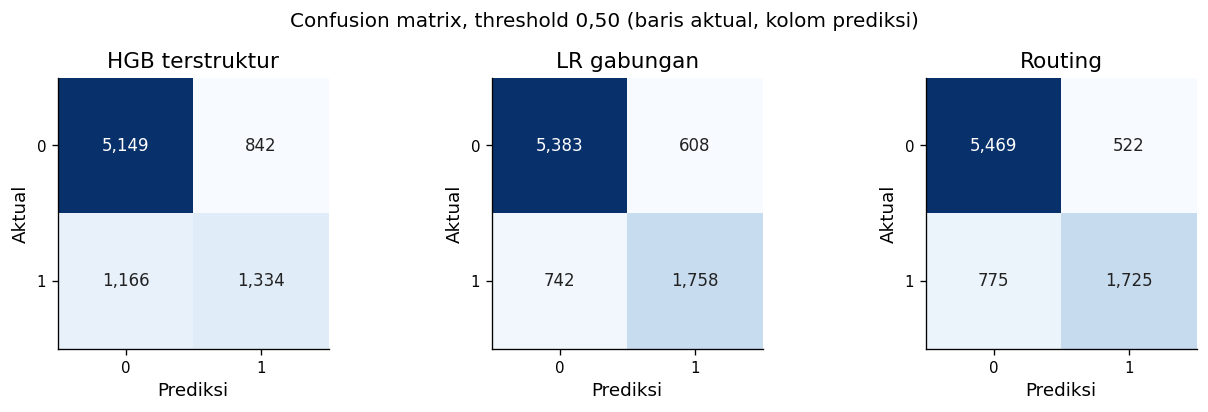

model,HGB terstruktur,LR gabungan,Routing
cycle,,,
76,0.7273,0.7937,0.7968
77,0.7268,0.7916,0.8014
78,0.6773,0.8115,0.8175
79,0.6762,0.8214,0.8213


,Equal-cycle Macro F1
model,
HGB terstruktur,0.7019
LR gabungan,0.8046
Routing,0.8093


C1_B      0.703700
C2_B      0.805571
C4_HGB    0.810384
Name: Independent sklearn Macro F1, dtype: float64

In [17]:
metric_results = {
    name: binary_metrics(y_valid, probability, threshold)
    for name, probability in probabilities.items()
}
overall_rows = []
class_rows = []
for name, metrics in metric_results.items():
    overall_rows.append(
        {
            "model": MODEL_LABELS[name],
            "n": metrics["n"],
            "Macro F1": metrics["macro_f1"],
            "F1 kelas 0": metrics["per_class"][0]["f1"],
            "F1 kelas 1": metrics["per_class"][1]["f1"],
            "AP": metrics["average_precision"],
            "positive aktual": metrics["positive_rate"],
            "positive prediksi": metrics["positive_prediction_rate"],
        }
    )
    for class_metrics in metrics["per_class"]:
        class_rows.append(
            {
                "model": MODEL_LABELS[name],
                "kelas": class_metrics["label"],
                "support": class_metrics["support"],
                "precision": class_metrics["precision"],
                "recall": class_metrics["recall"],
                "F1": class_metrics["f1"],
            }
        )
overall_table = pd.DataFrame(overall_rows).set_index("model")
display(
    overall_table.style.format(
        "{:.4f}",
        subset=[
            "Macro F1", "F1 kelas 0", "F1 kelas 1", "AP",
            "positive aktual", "positive prediksi",
        ],
    )
)
display(
    pd.DataFrame(class_rows).style.format(
        {"precision": "{:.4f}", "recall": "{:.4f}", "F1": "{:.4f}"}
    )
)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for axis, (name, metrics) in zip(axes, metric_results.items()):
    matrix = np.asarray(metrics["confusion_matrix"])
    axis.imshow(matrix, cmap="Blues")
    axis.set(
        title=MODEL_LABELS[name],
        xlabel="Prediksi",
        ylabel="Aktual",
        xticks=[0, 1],
        yticks=[0, 1],
    )
    for (row, column), value in np.ndenumerate(matrix):
        color = "white" if value > matrix.max() * 0.55 else "#222222"
        axis.text(column, row, f"{value:,}", ha="center", va="center", color=color)
fig.suptitle("Confusion matrix, threshold 0,50 (baris aktual, kolom prediksi)")
plt.tight_layout()
plt.show()

cycle_rows = []
for name, probability in probabilities.items():
    for cycle in sorted(np.unique(validation_cycles)):
        mask = validation_cycles == cycle
        metrics = binary_metrics(y_valid[mask], probability[mask], threshold)
        cycle_rows.append(
            {
                "model": MODEL_LABELS[name],
                "cycle": int(cycle),
                "n": int(mask.sum()),
                "Macro F1": metrics["macro_f1"],
                "prevalence": metrics["positive_rate"],
                "positive prediksi": metrics["positive_prediction_rate"],
            }
        )
cycle_table = pd.DataFrame(cycle_rows)
display(cycle_table.pivot(index="cycle", columns="model", values="Macro F1").round(4))
display(
    cycle_table.groupby("model")["Macro F1"]
    .mean()
    .rename("Equal-cycle Macro F1")
    .to_frame()
    .round(4)
)

independent_macro_f1 = {}
for name, probability in probabilities.items():
    independent_macro_f1[name] = float(
        f1_score(
            y_valid,
            (probability >= 0.50).astype(np.int8),
            labels=[0, 1],
            average="macro",
            zero_division=0,
        )
    )
    assert np.isclose(
        independent_macro_f1[name], metric_results[name]["macro_f1"], rtol=0, atol=1e-12
    )
assert np.array_equal(probability_c4hgb[~missing_valid], probability_c2b[~missing_valid])
assert np.array_equal(probability_c4hgb[missing_valid], probability_c1b[missing_valid])
display(pd.Series(independent_macro_f1, name="Independent sklearn Macro F1"))


Routing mengurangi false positive dari **608 menjadi 522**, tetapi true positive juga turun dari **1.758 menjadi 1.725** dibanding LR gabungan (C2_B). Jadi, peningkatan keputusan memiliki trade-off: lebih sedikit alarm salah dengan sedikit kehilangan deteksi positif.

model,HGB terstruktur,LR gabungan,Routing
kelompok,,,
EF0,0.6715,0.8033,0.8078
EF1,0.7354,0.7970,0.8011
stream kosong,0.7466,0.6775,0.7466
stream tersedia,0.7007,0.8147,0.8147


,kelompok,model,n,Macro F1,F1 kelas 0,F1 kelas 1,FP,FN
0,stream kosong,HGB terstruktur,526,0.7466,0.8502,0.6431,40,71
1,stream kosong,LR gabungan,526,0.6775,0.7363,0.6186,126,38
2,stream kosong,Routing,526,0.7466,0.8502,0.6431,40,71
3,stream tersedia,HGB terstruktur,7965,0.7007,0.8360,0.5654,802,1095
4,stream tersedia,LR gabungan,7965,0.8147,0.8968,0.7326,482,704
5,stream tersedia,Routing,7965,0.8147,0.8968,0.7326,482,704


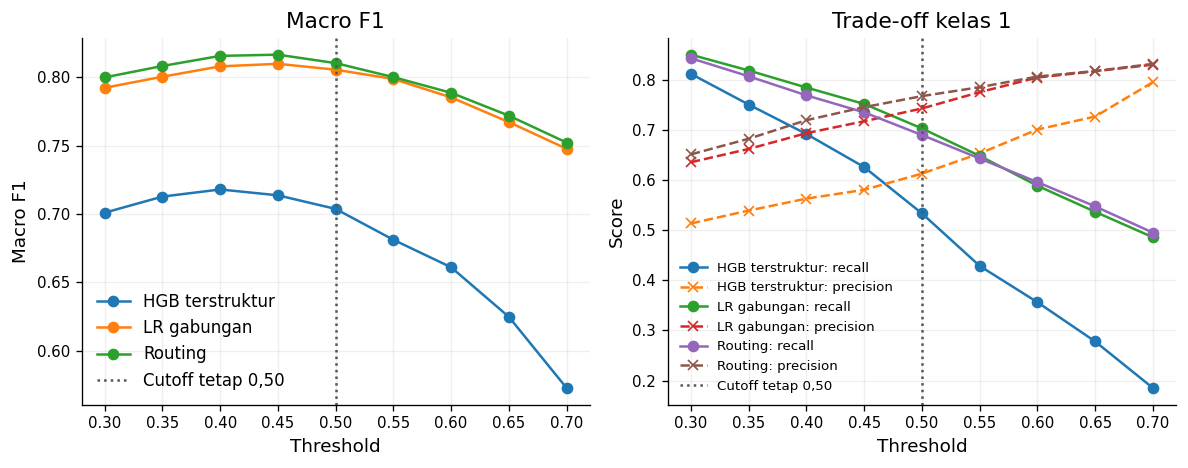

,model,threshold,Macro F1,precision class 1,recall class 1,positive prediction rate
4,HGB terstruktur,0.5,0.7037,0.6131,0.5336,0.2563
13,LR gabungan,0.5,0.8056,0.7430,0.7032,0.2786
22,Routing,0.5,0.8104,0.7677,0.6900,0.2646


In [18]:
subgroup_masks = {
    "stream kosong": missing_valid,
    "stream tersedia": ~missing_valid,
    "EF0": valid_frame["entry_friction"].eq(0).to_numpy(),
    "EF1": valid_frame["entry_friction"].eq(1).to_numpy(),
}
subgroup_rows = []
for group, mask in subgroup_masks.items():
    for name, probability in probabilities.items():
        metrics = binary_metrics(y_valid[mask], probability[mask], threshold)
        subgroup_rows.append(
            {
                "kelompok": group,
                "model": MODEL_LABELS[name],
                "n": metrics["n"],
                "Macro F1": metrics["macro_f1"],
                "F1 kelas 0": metrics["per_class"][0]["f1"],
                "F1 kelas 1": metrics["per_class"][1]["f1"],
                "FP": metrics["false_positive"],
                "FN": metrics["false_negative"],
            }
        )
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.pivot(index="kelompok", columns="model", values="Macro F1").round(4))
display(subgroup_table[subgroup_table["kelompok"].str.startswith("stream")].round(4))

threshold_rows = []
cutoff_grid = np.round(np.arange(0.30, 0.701, 0.05), 2)
for name, probability in probabilities.items():
    for cutoff in cutoff_grid:
        metrics = binary_metrics(y_valid, probability, float(cutoff))
        threshold_rows.append(
            {
                "model": MODEL_LABELS[name],
                "threshold": cutoff,
                "Macro F1": metrics["macro_f1"],
                "precision class 1": metrics["per_class"][1]["precision"],
                "recall class 1": metrics["per_class"][1]["recall"],
                "positive prediction rate": metrics["positive_prediction_rate"],
            }
        )
threshold_table = pd.DataFrame(threshold_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, group in threshold_table.groupby("model"):
    axes[0].plot(group.threshold, group["Macro F1"], marker="o", label=name)
    axes[1].plot(
        group.threshold, group["recall class 1"], marker="o", label=f"{name}: recall"
    )
    axes[1].plot(
        group.threshold,
        group["precision class 1"],
        marker="x",
        linestyle="--",
        label=f"{name}: precision",
    )
for axis in axes:
    axis.axvline(0.50, color="#555555", linestyle=":", label="Cutoff tetap 0,50")
    axis.set_xlabel("Threshold")
    axis.grid(alpha=0.2)
axes[0].set(title="Macro F1", ylabel="Macro F1")
axes[1].set(title="Trade-off kelas 1", ylabel="Score")
axes[0].legend(frameon=False)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
display(threshold_table[threshold_table.threshold.eq(0.50)].round(4))


Kurva threshold hanya diagnostik; keputusan tetap **0,50**.

### Recipe individual dan Kaggle

- Teks kosong: HGB terstruktur (C1_B).
- Teks terisi: LR gabungan (C2_B).
- Routing hanya memakai ketersediaan fitur; ID dan target tidak menjadi predictor.

Skor public di bawah berasal dari manifest submission historis, terpisah dari validasi temporal.

In [19]:
assert HISTORICAL_KAGGLE["status"] == "COMPLETE"
assert HISTORICAL_KAGGLE["reference"] == 57808225
assert float(HISTORICAL_KAGGLE["public_score"]) == 0.82641
historical_final = pd.DataFrame(
    [
        {
            "recipe": "C4_HGB",
            "threshold": 0.50,
            "Kaggle public score historis": HISTORICAL_KAGGLE["public_score"],
            "submission reference": HISTORICAL_KAGGLE["reference"],
            "W6 Macro F1 baru dihitung": metric_results["C4_HGB"]["macro_f1"],
            "W6 probability cocok": probability_hashes["C4_HGB"]
            == HISTORICAL_W6_HASHES["C4_HGB"],
        }
    ]
)
display(historical_final)


,recipe,threshold,Kaggle public score historis,submission reference,W6 Macro F1 baru dihitung,W6 probability cocok
0,C4_HGB,0.5,0.82641,57808225,0.810384,True


In [20]:
core_receipt = {
    "task": "classification",
    "fit_cycles": list(FIT_CYCLES),
    "validation_cycles": list(VALID_CYCLES),
    "fit_rows": len(fit_rows),
    "validation_rows": len(valid_rows),
    "threshold": threshold,
    "macro_f1": {
        name: float(metrics["macro_f1"])
        for name, metrics in metric_results.items()
    },
    "probability_sha256": probability_hashes,
    "matches_historical_probabilities": bool(hash_checks["identik"].all()),
    "fit_preprocessing_only_train": True,
    "test_used_in_core": False,
}
display(pd.Series(core_receipt, name="W6 replay receipt"))
print("CORE_RECEIPT_JSON=" + json.dumps(core_receipt, sort_keys=True))


task                                                                   classification
fit_cycles                                                                   [47, 75]
validation_cycles                                                            [76, 79]
fit_rows                                                                        42117
validation_rows                                                                  8491
threshold                                                                         0.5
macro_f1                            {'C1_B': 0.703700351612718, 'C2_B': 0.80557091...
probability_sha256                  {'C1_B': 'a21ba8ffa0396afe9f8d7ee78bbcccc5d602...
matches_historical_probabilities                                                 True
fit_preprocessing_only_train                                                     True
test_used_in_core                                                               False
Name: W6 replay receipt, dtype: object

CORE_RECEIPT_JSON={"fit_cycles": [47, 75], "fit_preprocessing_only_train": true, "fit_rows": 42117, "macro_f1": {"C1_B": 0.703700351612718, "C2_B": 0.8055709115215474, "C4_HGB": 0.810383724597016}, "matches_historical_probabilities": true, "probability_sha256": {"C1_B": "a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1cb708ddc208f613095", "C2_B": "01a886bb391728b58cb3504946d620efabc4859ea55585d36b76028793feb1f4", "C4_HGB": "fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c0a793767733b9d1130"}, "task": "classification", "test_used_in_core": false, "threshold": 0.5, "validation_cycles": [76, 79], "validation_rows": 8491}


## 7. Melatih model akhir dan membuat prediksi Test

Evaluasi sebelumnya memisahkan data masa lalu untuk melatih model dan cycle berikutnya untuk mengukur error. Setelah pendekatan dipilih, model dilatih ulang memakai **seluruh 50.608 baris Train**, agar prediksi official Test memanfaatkan semua label yang tersedia. Tahap inilah yang disebut **refit penuh**.

Sel di bawah menjalankannya jika `RUN_FULL_TRAIN_INFERENCE = True`: seluruh preprocessing dipelajari ulang dari Train, kemudian model memprediksi Test dan menyimpan CSV lokal. Nilainya dibiarkan `False` saat demonstrasi agar tidak mengulang pembuatan file; **evaluasi temporal di bagian sebelumnya tetap dijalankan**.

Tahap ini tidak menghasilkan skor validasi baru karena label Test tidak tersedia. Angka public Kaggle yang ditampilkan berasal dari submission historis, bukan dihitung oleh sel ini.

In [21]:
RUN_FULL_TRAIN_INFERENCE = False
if RUN_FULL_TRAIN_INFERENCE:
    if DATA_FILES["test"] is None or DATA_FILES["sample"] is None:
        raise FileNotFoundError("Official Test.csv dan SampleSubmission.csv diperlukan.")
    assert sha256_file(DATA_FILES["test"]) == (
        "4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c"
    )
    assert sha256_file(DATA_FILES["sample"]) == (
        "889f97d69659a64945421d841dcf96e5813020606f29b2992d4b9560cecdcba7"
    )
    test = pd.read_csv(DATA_FILES["test"])
    sample = pd.read_csv(DATA_FILES["sample"])
    assert sample.columns.tolist() == ["record_id", "artifact_signal"]
    assert len(test) == len(sample) == 29421
    assert test["record_id"].is_unique and sample["record_id"].is_unique
    assert test["record_id"].tolist() == sample["record_id"].tolist()
    assert "artifact_signal" not in test
    assert set(test.columns) == set(train.columns) - {"artifact_signal"}
    assert not set(train.record_id) & set(test.record_id)
    assert test.cycle_code.between(80, 91).all()

    full_y = train["artifact_signal"].to_numpy(dtype=np.int8, copy=True)
    full_c2b = ClassificationRecipe("C2_B")
    full_c1b = ClassificationRecipe("C1_B")
    with threadpool_limits(limits=2):
        full_c2b.fit(train.loc[:, list(HYBRID_FEATURES)], full_y)
        test_p_c2b = full_c2b.predict_proba(test.loc[:, list(HYBRID_FEATURES)])
        full_c1b.fit(train.loc[:, list(STRUCTURED_FEATURES)], full_y)
        test_p_c1b = full_c1b.predict_proba(test.loc[:, list(STRUCTURED_FEATURES)])
    test_missing = stream_missing_mask(test)
    test_probability = np.where(test_missing, test_p_c1b, test_p_c2b)
    test_prediction = (test_probability >= 0.50).astype(np.int8)
    assert test_prediction.shape == (29421,)
    assert set(np.unique(test_prediction)).issubset({0, 1})
    submission = pd.DataFrame(
        {"record_id": sample["record_id"], "artifact_signal": test_prediction}
    )
    assert submission.columns.tolist() == sample.columns.tolist()
    assert submission["record_id"].tolist() == sample["record_id"].tolist()
    assert submission["artifact_signal"].notna().all()

    output_path = Path(
        os.environ.get(
            "SAMUEL_CLASSIFICATION_PREDICTION_PATH",
            Path.cwd() / "classification_reproduced.csv",
        )
    ).expanduser()
    if not output_path.is_absolute():
        output_path = Path.cwd() / output_path
    output_path.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes = submission.to_csv(index=False).encode("utf-8")
    if output_path.exists() and output_path.read_bytes() != csv_bytes:
        raise FileExistsError("Output lokal berbeda; periksa sebelum mengganti file.")
    output_path.write_bytes(csv_bytes)
    print("CSV lokal dibuat, belum diunggah:", output_path.resolve())
    print("Baris:", len(submission), "| class 1:", int(test_prediction.sum()))
else:
    print("Flag False: full-Train refit dilewati dan CSV submission tidak dibuat.")


Flag False: full-Train refit dilewati dan CSV submission tidak dibuat.


## 8. Kesimpulan

Laporan dengan teks kosong memiliki proporsi `artifact_signal = 1` lebih tinggi secara agregat (**38,13% vs 34,47%**). Akan tetapi, setelah komposisi periode dan volume disamakan, selisih berbalik menjadi sekitar **-2,2 sampai -2,3 poin persentase**. Jawaban EDA bergantung pada komposisi laporan; status teks kosong saja belum cukup untuk menjelaskan proporsi label.

Pada modeling, teks dan fitur structured saling melengkapi. Hybrid LR gabungan (C2_B) lebih kuat secara keseluruhan, tetapi lebih lemah saat teks kosong. Karena itu, Routing (C4_HGB) mempertahankan hybrid pada teks terisi dan memakai structured HGB pada teks kosong. Pilihan ini memberi **Macro F1 0,8255 primary dan 0,7968 H12**, dibanding LR gabungan (C2_B) **0,8206 dan 0,7886**. Threshold tetap 0,50 karena penyesuaian threshold tidak konsisten memperbaiki primary.

Public benchmark approach individual ini adalah **0,82641**. Nilai tersebut merupakan evaluasi sebagian Test dan berbeda dari skor internal. EDA memberi pemahaman tentang komposisi data; bukti manfaat routing berasal dari evaluasi model yang terpisah.

Kesimpulan tetap terbatas pada data yang dianalisis. Kelompok volume masih kasar, seluruh window sudah digunakan dalam development, dan H12 tidak independen dari primary. Hasil tidak membuktikan sebab-akibat maupun menjamin performa pada private Test.